# 01 · Exploring the PPI network

This notebook characterises the interaction network before any modelling: its size and connectivity, the
heavy-tailed degree distribution typical of interactomes, hubs and bottlenecks, local structure, and the
confidence scores attached to each interaction.

The bundled dataset (`data/raw/sample_ppi_edges.tsv`) is a **synthetic** network grown with the
duplication-divergence model of PPI evolution (see `data/README.md`). Every cell runs unchanged on a real
STRING or BioGRID edge list: point `DATA` at your file.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src.evaluate import INK, PALETTE, SEQUENTIAL, plot_style
from src.feature_extractor import compute_node_metrics
from src.graph_builder import build_graph, graph_summary, load_edge_list

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)

DATA = ROOT / "data" / "raw" / "sample_ppi_edges.tsv"
edges = load_edge_list(DATA)
G = build_graph(edges)
print(f"{G.number_of_nodes():,} proteins, {G.number_of_edges():,} interactions")

2,000 proteins, 7,518 interactions


## 1. Global statistics

In [2]:
summary = pd.Series(graph_summary(G), name="value")
summary.to_frame()

,value
proteins,2000.000
interactions,7518.000
density,0.004
mean_degree,7.518
max_degree,162.000
average_clustering,0.126
transitivity,0.052
connected_components,1.000
largest_component_fraction,1.000
degree_assortativity,-0.037


The network is very sparse (density well below 1%), forms a single connected component, and its
average clustering is far higher than a random graph of the same density would have (≈ density), which is
the signature of local, complex-like structure. The slightly negative degree assortativity means hubs tend to
interact with low-degree proteins, as reported for yeast and human interactomes.

## 2. Degree distribution

The complementary cumulative distribution $P(K \ge k)$ on log-log axes avoids the noisy tail of a
histogram. An Erdős–Rényi graph with the same number of proteins and interactions is shown for reference.

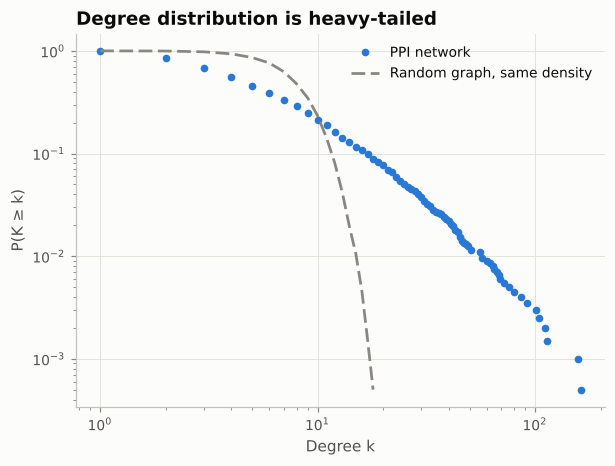

mean degree 7.5, median 4, max 162
proteins with a single partner: 14.8%


In [3]:
def ccdf(values):
    values = np.sort(np.asarray(values))
    unique, first = np.unique(values, return_index=True)
    return unique, 1 - first / len(values)

degrees = np.array([d for _, d in G.degree()])
random_graph = nx.gnm_random_graph(G.number_of_nodes(), G.number_of_edges(), seed=0)
random_degrees = np.array([d for _, d in random_graph.degree()])

with plot_style():
    fig, ax = plt.subplots(figsize=(6.2, 4.4))
    k, p = ccdf(degrees)
    ax.loglog(k, p, marker="o", markersize=4, linestyle="none", color=PALETTE[0], label="PPI network")
    k, p = ccdf(random_degrees[random_degrees > 0])
    ax.loglog(k, p, color=INK["muted"], linestyle=(0, (5, 2)), label="Random graph, same density")
    ax.set(xlabel="Degree k", ylabel="P(K ≥ k)")
    ax.set_title("Degree distribution is heavy-tailed")
    ax.legend()
    plt.show()

print(f"mean degree {degrees.mean():.1f}, median {np.median(degrees):.0f}, max {degrees.max()}")
print(f"proteins with a single partner: {(degrees == 1).mean():.1%}")

Most proteins have only a handful of partners while a few hubs have well over a hundred: the random
graph's distribution collapses within a narrow range, whereas the PPI network spans two orders of magnitude.
This heterogeneity is why degree-based features (and preferential attachment) carry signal, and why
link-prediction scores must be normalised for degree.

## 3. Clustering spectrum

Average clustering of proteins grouped by degree, $C(k)$. A decreasing $C(k)$ indicates hierarchical
organisation: low-degree proteins sit in tight modules while hubs bridge modules whose members do not
interact with each other.

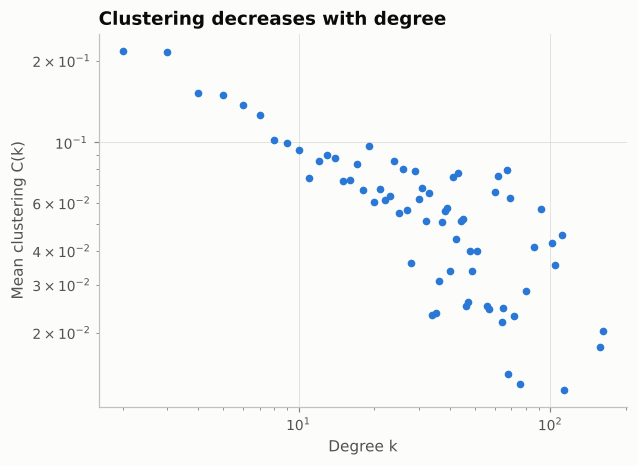

In [4]:
clustering = nx.clustering(G)
spectrum = (
    pd.DataFrame({"degree": dict(G.degree()), "clustering": clustering})
    .query("degree >= 2")
    .groupby("degree")["clustering"]
    .agg(["mean", "size"])
)

with plot_style():
    fig, ax = plt.subplots(figsize=(6.2, 4.4))
    positive = spectrum[spectrum["mean"] > 0]
    ax.loglog(positive.index, positive["mean"], marker="o", markersize=4, linestyle="none", color=PALETTE[0])
    ax.set(xlabel="Degree k", ylabel="Mean clustering C(k)")
    ax.set_title("Clustering decreases with degree")
    plt.show()

## 4. Hubs and bottlenecks

Degree measures how many partners a protein has; betweenness measures how many shortest paths run through
it. Proteins with high betweenness but modest degree are *bottlenecks* connecting otherwise separate
modules; in real interactomes they are enriched for essential genes.

In [5]:
metrics = compute_node_metrics(G)
metrics.sort_values("betweenness", ascending=False).head(10)

,degree,clustering,betweenness,closeness
protein,,,,
P01268,158.0,0.018,0.152,0.394
P01426,162.0,0.020,0.096,0.384
P01587,113.0,0.012,0.096,0.359
P01141,104.0,0.035,0.082,0.390
P01977,101.0,0.043,0.064,0.386
P01980,111.0,0.046,0.064,0.382
P01628,72.0,0.023,0.058,0.352
P00429,92.0,0.057,0.053,0.378
P01236,86.0,0.041,0.046,0.380


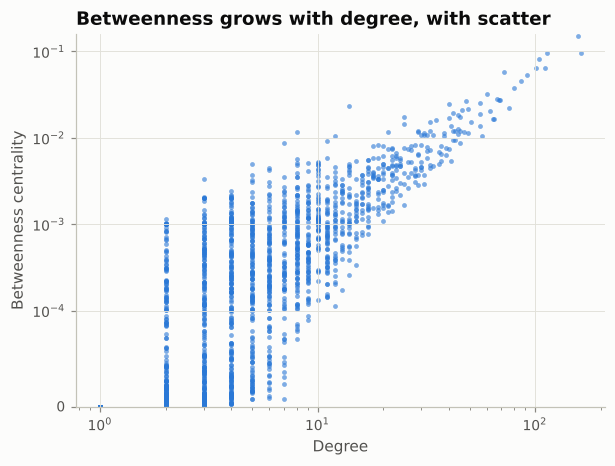

Spearman correlation between node metrics:


,degree,clustering,betweenness,closeness
degree,1.000,0.425,0.853,0.676
clustering,0.425,1.000,0.231,0.250
betweenness,0.853,0.231,1.000,0.580
closeness,0.676,0.250,0.580,1.000


In [6]:
with plot_style():
    fig, ax = plt.subplots(figsize=(6.2, 4.4))
    ax.scatter(metrics["degree"], metrics["betweenness"], s=10, alpha=0.6, color=PALETTE[0], linewidths=0)
    ax.set(xscale="log", xlabel="Degree", ylabel="Betweenness centrality")
    ax.set_yscale("symlog", linthresh=1e-4)
    ax.set_ylim(bottom=0)
    ax.set_title("Betweenness grows with degree, with scatter")
    plt.show()

print("Spearman correlation between node metrics:")
metrics.corr(method="spearman")

## 5. A local neighbourhood

The two-step neighbourhood of a typical protein (degree near the median). Node size follows degree,
colour follows distance from the centre protein.

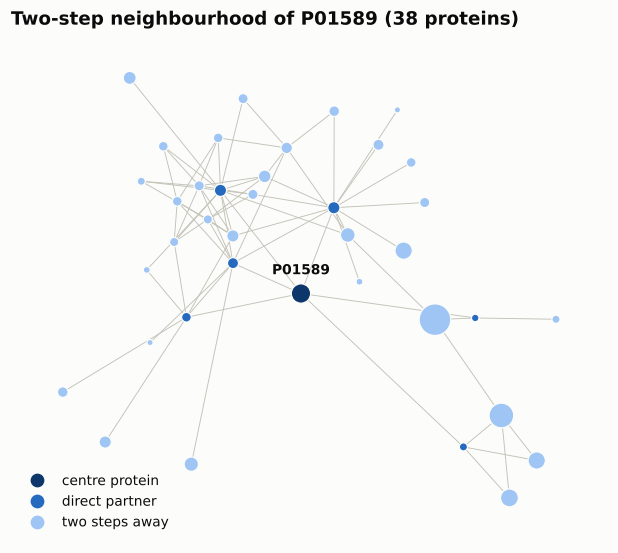

In [7]:
rng = np.random.default_rng(3)
typical = [n for n, d in G.degree() if 5 <= d <= 7]
centre = typical[rng.integers(len(typical))]
ego = nx.ego_graph(G, centre, radius=2)
distance = nx.single_source_shortest_path_length(ego, centre)
colours = [SEQUENTIAL[6], SEQUENTIAL[4], SEQUENTIAL[1]]

with plot_style():
    fig, ax = plt.subplots(figsize=(7, 6))
    pos = nx.spring_layout(ego, seed=7, k=0.35)
    nx.draw_networkx_edges(ego, pos, ax=ax, edge_color=INK["axis"], width=0.6)
    nx.draw_networkx_nodes(
        ego, pos, ax=ax,
        node_size=[160 if n == centre else 12 + 4 * G.degree(n) for n in ego],
        node_color=[colours[distance[n]] for n in ego],
        edgecolors=INK["surface"], linewidths=0.8,
    )
    label_pos = {centre: pos[centre] + np.array([0, 0.08])}
    nx.draw_networkx_labels(ego, label_pos, labels={centre: centre}, ax=ax, font_size=9,
                            font_color=INK["primary"], font_weight="bold")
    handles = [
        plt.Line2D([], [], marker="o", linestyle="none", markersize=8, color=c, label=l)
        for c, l in zip(colours, ["centre protein", "direct partner", "two steps away"])
    ]
    ax.legend(handles=handles, loc="lower left")
    ax.set_title(f"Two-step neighbourhood of {centre} ({ego.number_of_nodes()} proteins)")
    ax.axis("off")
    plt.show()

## 6. Interaction confidence scores

Experimental screens produce false positives, so databases attach a confidence score to each interaction
(STRING uses 0–1000). The synthetic sample also records whether an edge is a biological interaction or a
spurious "noise" hit, which lets us see what a score threshold buys.

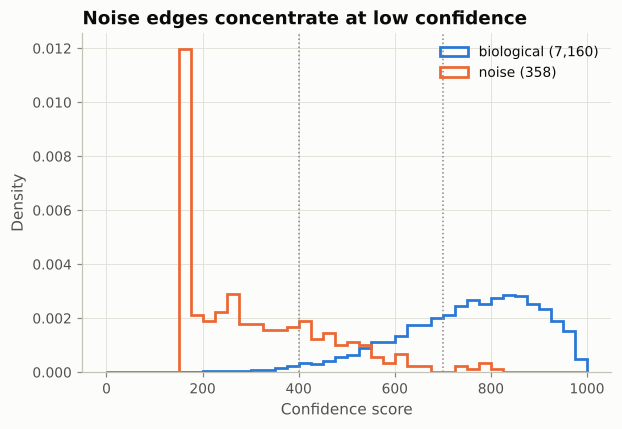

,interactions kept,biological kept,noise kept
min_score,,,
0,7518,1.000,1.000
400,7124,0.982,0.263
700,4842,0.675,0.020
900,1122,0.157,0.000


In [8]:
raw = pd.read_csv(DATA, sep="\t")

with plot_style():
    fig, ax = plt.subplots(figsize=(6.2, 4.0))
    bins = np.linspace(0, 1000, 41)
    for colour, (source, group) in zip(PALETTE, raw.groupby("source")):
        ax.hist(group["score"], bins=bins, histtype="step", linewidth=1.8, color=colour,
                label=f"{source} ({len(group):,})", density=True)
    for threshold in (400, 700):
        ax.axvline(threshold, color=INK["muted"], linewidth=1, linestyle=":")
    ax.set(xlabel="Confidence score", ylabel="Density")
    ax.set_title("Noise edges concentrate at low confidence")
    ax.legend()
    plt.show()

rows = []
for threshold in (0, 400, 700, 900):
    kept = raw[raw["score"] >= threshold]
    rows.append({
        "min_score": threshold,
        "interactions kept": len(kept),
        "biological kept": (kept["source"] == "biological").sum() / (raw["source"] == "biological").sum(),
        "noise kept": (kept["source"] == "noise").sum() / (raw["source"] == "noise").sum(),
    })
pd.DataFrame(rows).set_index("min_score")

(Scores are floored at 150, hence the spike of low-confidence noise at the left edge.) A threshold removes
most noise but also discards real interactions, a trade-off to tune per dataset
(pass `--min-score` to the pipeline). The default run keeps every edge, so the models must cope with noisy
input, as they would on raw screening data.

## Takeaways

* The network is sparse, small-world and heavy-tailed, so features must be robust to degree heterogeneity.
* Clustering is high but falls with degree: triangles alone will not explain every interaction.
* Notebook `02_feature_and_model_analysis.ipynb` builds on these observations to engineer pairwise features
  and train the classifiers.